# One API for cell-cell communication: `ov.single.run_ccc`

Cell-cell communication (CCC) tools differ in their ligand-receptor database, in how they score an interaction and in how they decide significance, so the same dataset can give quite different answers. `ov.single.run_ccc` runs any of them through one call and returns the same communication AnnData, so that every `ov.pl.ccc_*` plot works for every method, several methods can be combined into a consensus, and their agreement can be measured.

| `method=` | Principle | Input | Score | Reference |
|---|---|---|---|---|
| `'cellchat'` | Law of mass action on trimean expression, cofactors, label permutations | log-normalised | probability | Jin *et al.*, *Nat Commun* 2021 |
| `'cellphonedb'` | Mean L/R expression, label permutations | log-normalised | expression | Efremova *et al.*, *Nat Protoc* 2020 |
| `'liana'` | Robust rank aggregate of several methods | log-normalised | rank | Dimitrov *et al.*, *Nat Cell Biol* 2024 |
| `'fastccc'` | Analytic (permutation-free) null of CellPhoneDB-style scores | log-normalised | expression | *Nat Commun* 2025 |
| `'secact'` | Ridge-regression activity of 1,170 secreted proteins in the receivers | raw counts | activity | Ru *et al.*, *Nat Methods* 2026 |
| `'cytosignal'` | Diffusion / contact LR scores at cellular resolution (spatial) | raw counts | expression | Liu *et al.*, *Nat Genet* 2026 |
| `'commot'` | Collective optimal transport (spatial) | log-normalised | expression | Cang *et al.*, *Nat Methods* 2023 |

CellChat, FastCCC, SecAct and CytoSignal are re-implemented in OmicVerse (NumPy/PyTorch, no R and no scanpy) and reproduce the original packages to floating-point precision; CellPhoneDB and LIANA call the original Python packages. Each backend picks its own input (log-normalised `X` or `layers['counts']`).

This tutorial covers
1. a single method and the common output;
2. several methods with a consensus;
3. how far the methods agree (`ov.single.compare_ccc`, `ov.pl.ccc_compare`);
4. spatial communication with `ov.space.run_ccc` on Slide-tags mouse brain.

In [1]:
import pandas as pd
import omicverse as ov

ov.plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)
   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              
🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.


## 1. Data

We reuse the maternal-fetal interface dataset of the [CellPhoneDB](t_ccc_cellphonedb.ipynb) and [CellChat](t_ccc_cellchat.ipynb) tutorials (download `data_tutorial.zip` from the [CellPhoneDB repository](https://github.com/ventolab/CellphoneDB/tree/master/notebooks) into `data/cpdb/`). The matrix is library-size normalised and log-transformed.

In [2]:
adata = ov.read('data/cpdb/normalised_log_counts.h5ad')
keep = ['eEVT', 'iEVT', 'EVT_1', 'EVT_2', 'DC', 'dNK1', 'dNK2', 'dNK3',
        'VCT', 'VCT_CCC', 'VCT_fusing', 'VCT_p', 'GC', 'SCT']
adata = adata[adata.obs['cell_labels'].isin(keep)].copy()
adata

AnnData object with n_obs × n_vars = 1065 × 30800
    obs: 'n_genes', 'n_counts', 'cell_labels'
    var: 'gene_ids', 'feature_types'
    uns: 'neighbors_scVI_n_latent_14_sample_n_layers_3', 'neighbors_scVI_n_latent_20_sample_n_layers_3', 'umap'
    obsm: 'X_scVI_n_latent_14_sample_n_layers_3', 'X_scVI_n_latent_20_sample_n_layers_3', 'X_umap', 'X_umap_scVI_n_latent_14_sample_n_layers_3', 'X_umap_scVI_n_latent_20_sample_n_layers_3'
    obsp: 'neighbors_scVI_n_latent_14_sample_n_layers_3_connectivities', 'neighbors_scVI_n_latent_14_sample_n_layers_3_distances', 'neighbors_scVI_n_latent_20_sample_n_layers_3_connectivities', 'neighbors_scVI_n_latent_20_sample_n_layers_3_distances'

In [3]:
ov.single.available_ccc_methods()

['cellchat',
 'cellphonedb',
 'commot',
 'cytosignal',
 'fastccc',
 'liana',
 'secact']

In [4]:
cpdb_zip = ov.single.download_cellphonedb_database('./cellphonedb.zip')

✅ CellPhoneDB database already exists: cellphonedb.zip


## 2. One method

`run_ccc` returns a communication AnnData: `obs` are sender|receiver pairs, `var` the ligand-receptor pairs, `layers['means']` the method's score and `layers['pvalues']` its p-value. Groups with ≤ `min_cells` (default 10) cells are not analysed by any method. FastCCC computes its p-values analytically, so it takes seconds.

In [5]:
comm_fast = ov.single.run_ccc(
    adata, 'cell_labels', method='fastccc',
    method_kwargs={'cpdb_file_path': cpdb_zip},
)
comm_fast

AnnData object with n_obs × n_vars = 169 × 452
    obs: 'sender', 'receiver', 'cell_type_pair'
    var: 'interaction_name', 'interacting_pair', 'interaction_name_2', 'classification', 'gene_a', 'gene_b', 'ligand_genes', 'receptor_genes', 'annotation'
    uns: 'comm_source', 'comm_score_scale'
    layers: 'means', 'pvalues'

Every method also writes a *long table* with the same columns. `ligand_genes` / `receptor_genes` list the subunit genes of complexes, which is how interactions are matched across databases.

In [6]:
ov.single.get_ccc(adata, method='fastccc', as_long=True, significant_only=True)\
    .sort_values('score', ascending=False).head()

,source,target,ligand,receptor,ligand_genes,receptor_genes,interaction,pathway,annotation,score,pvalue,significant
1668,GC,iEVT,FN1,integrin_a5b1_complex,FN1,ITGA5_ITGB1,FN1_integrin_a5b1_complex,Adhesion by Fibronectin,Adhesion-Adhesion,3.042999,3.219647e-15,True
1161,GC,GC,FN1,integrin_a5b1_complex,FN1,ITGA5_ITGB1,FN1_integrin_a5b1_complex,Adhesion by Fibronectin,Adhesion-Adhesion,3.015463,3.219647e-15,True
1111,GC,EVT_2,FN1,integrin_a5b1_complex,FN1,ITGA5_ITGB1,FN1_integrin_a5b1_complex,Adhesion by Fibronectin,Adhesion-Adhesion,2.936534,3.330669e-15,True
6152,iEVT,iEVT,FN1,integrin_a5b1_complex,FN1,ITGA5_ITGB1,FN1_integrin_a5b1_complex,Adhesion by Fibronectin,Adhesion-Adhesion,2.906182,0.000000e+00,True
5637,iEVT,GC,FN1,integrin_a5b1_complex,FN1,ITGA5_ITGB1,FN1_integrin_a5b1_complex,Adhesion by Fibronectin,Adhesion-Adhesion,2.878646,0.000000e+00,True


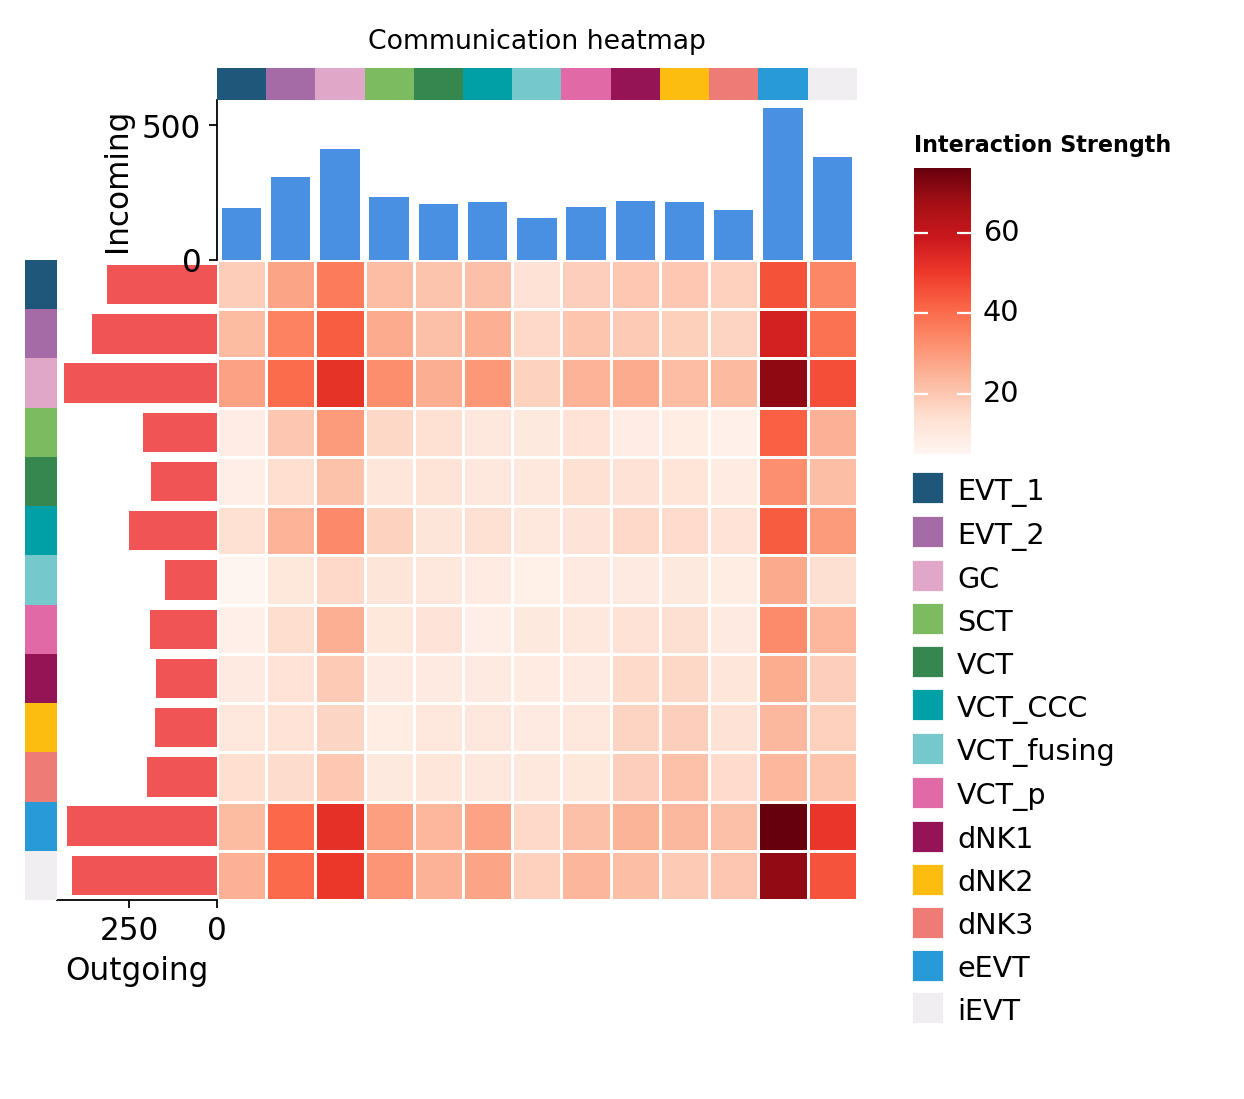

In [7]:
fig, ax = ov.pl.ccc_heatmap(
    comm_fast, plot_type='heatmap', display_by='aggregation', cmap='Reds', show=False,
)

## 3. Several methods and a consensus

With a list of methods `run_ccc` runs each one and builds a consensus: every method ranks its interactions by score, and the ranks are combined by **robust rank aggregation** (RRA; `pvalue` = RRA ρ). `consensus='vote'` instead calls an interaction when at least `min_methods` methods call it. Method-specific options go into `method_kwargs`; shared ones (`n_perms`, `pvalue_threshold`, `seed`, `min_cells`) apply to all.

In [8]:
comm = ov.single.run_ccc(
    adata, 'cell_labels',
    method=['cellchat', 'cellphonedb', 'liana', 'fastccc'],
    consensus='rra', seed=0, progress=False,
    method_kwargs={'cellphonedb': {'cpdb_file_path': cpdb_zip, 'threads': 8},
                   'fastccc': {'cpdb_file_path': cpdb_zip}},
)
comm

🔬 Starting CellPhoneDB analysis...
✅ Valid CellPhoneDB database found: cellphonedb.zip (0.1 MB)
   - Original data: 1058 cells, 30800 genes
   - Cell types passing 0.0% threshold: 13
   - Minimum cells required: 0
   - After filtering: 1058 cells, 30800 genes
   - After preprocessing: 1058 cells, 19608 genes
   - Temporary directory: /tmp/cpdb_temp_uv434rdl
   - Output directory: /tmp/cpdb_results_ql2zvoto


   - Created temporary input files
   - Running CellPhoneDB statistical analysis...
Reading user files...


The following user files were loaded successfully:
/tmp/cpdb_temp_uv434rdl/counts_matrix.h5ad
/tmp/cpdb_temp_uv434rdl/metadata.tsv
[ ][CORE][11/10/26-13:39:58][INFO] [Cluster Statistical Analysis] Threshold:0.1 Iterations:1000 Debug-seed:0 Threads:8 Precision:3


[ ][CORE][11/10/26-13:39:58][WARNING] Debug random seed enabled. Set to 0


[ ][CORE][11/10/26-13:39:59][INFO] Running Real Analysis


...

[ ][CORE][11/10/26-13:40:04][INFO] Scoring interactions: Calculating mean expression of each gene per group/cell type..


[ ][CORE][11/10/26-13:40:04][INFO] Scoring interactions: Calculating scores for all interactions and cell types..


Saved deconvoluted to /tmp/cpdb_results_ql2zvoto/statistical_analysis_deconvoluted_10_11_2026_134012.txt
Saved deconvoluted_percents to /tmp/cpdb_results_ql2zvoto/statistical_analysis_deconvoluted_percents_10_11_2026_134012.txt
Saved means to /tmp/cpdb_results_ql2zvoto/statistical_analysis_means_10_11_2026_134012.txt
Saved pvalues to /tmp/cpdb_results_ql2zvoto/statistical_analysis_pvalues_10_11_2026_134012.txt


Saved significant_means to /tmp/cpdb_results_ql2zvoto/statistical_analysis_significant_means_10_11_2026_134012.txt
Saved interaction_scores to /tmp/cpdb_results_ql2zvoto/statistical_analysis_interaction_scores_10_11_2026_134012.txt
   - CellPhoneDB analysis completed successfully!
   - Formatting results for visualization...
   - Found 13 info columns and 169 cell type pairs
   - Found 122 pathway classifications
   - Created visualization AnnData: (169, 1432)
   - Cell interactions: 169
   - L-R pairs: 1432
   - Cleaned up temporary directory: /tmp/cpdb_temp_uv434rdl
✅ CellPhoneDB analysis pipeline completed!


AnnData object with n_obs × n_vars = 169 × 2430
    obs: 'sender', 'receiver', 'cell_type_pair'
    var: 'interaction_name', 'interacting_pair', 'interaction_name_2', 'classification', 'gene_a', 'gene_b', 'ligand_genes', 'receptor_genes', 'annotation'
    uns: 'comm_source', 'comm_score_scale'
    layers: 'means', 'pvalues', 'cellchat_score', 'cellchat_pvalue', 'cellphonedb_score', 'cellphonedb_pvalue', 'liana_score', 'liana_pvalue', 'fastccc_score', 'fastccc_pvalue', 'n_methods_significant'

The consensus AnnData keeps each method's score and p-value as extra layers (`cellchat_score`, `cellphonedb_pvalue`, ...) and the number of methods calling each interaction (`n_methods_significant`).

In [9]:
cons = ov.single.get_ccc(adata, method='consensus', as_long=True)
cons.head(10)[['source', 'target', 'interaction', 'pathway', 'rra_rho', 'n_methods_significant']]

,source,target,interaction,pathway,rra_rho,n_methods_significant
0,GC,GC,FN1 - (ITGA5+ITGB1),FN1,2.710189e-14,4
1,GC,iEVT,FN1 - (ITGA5+ITGB1),FN1,1.372033e-13,4
2,iEVT,GC,FN1 - (ITGA5+ITGB1),FN1,4.336303e-13,4
3,iEVT,iEVT,FN1 - (ITGA5+ITGB1),FN1,1.058668e-12,4
4,GC,EVT_2,FN1 - (ITGA5+ITGB1),FN1,6.507165e-11,4
5,GC,eEVT,FN1 - (ITGA5+ITGB1),FN1,3.512405e-11,4
6,iEVT,EVT_2,FN1 - (ITGA5+ITGB1),FN1,2.207466e-10,4
7,iEVT,eEVT,FN1 - (ITGA5+ITGB1),FN1,1.778155e-10,4
8,EVT_2,iEVT,FN1 - (ITGA5+ITGB1),FN1,9.212404e-11,4
9,EVT_2,GC,FN1 - (ITGA5+ITGB1),FN1,2.472936e-10,4


All four methods call **fibronectin (FN1) – integrin α5β1** between glycogen cells (GC), invasive EVT (iEVT) and EVT_2 at the top of the consensus (RRA ρ < 1e-9). Fibronectin–α5β1 adhesion is the classic switch that lets extravillous trophoblast invade the decidua, so the consensus starts from a well-established biology.

Native results stay available for the method-specific helpers, e.g. CellChat's centrality on `adata.uns['cellchat_res']`, and any single method can be pulled out as its own communication AnnData:

In [10]:
comm_cellchat = ov.single.get_ccc(adata, method='cellchat')
centr = ov.single.cellchat_centrality(adata, signaling=['VEGF'])
centr['VEGF'][['outdeg', 'indeg', 'flowbet', 'info']].round(3)

,outdeg,indeg,flowbet,info
DC,0.000,0.000,0.000,0.000
EVT_1,0.769,0.411,3.182,0.121
EVT_2,0.431,0.656,2.120,0.141
GC,0.397,0.955,2.257,0.157
SCT,0.616,0.326,1.966,0.132
VCT,0.000,0.224,0.000,0.045
VCT_CCC,0.213,0.135,0.675,0.078
VCT_fusing,0.683,0.024,0.661,0.134
VCT_p,0.000,0.071,0.000,0.000
dNK1,0.000,0.000,0.000,0.000


## 4. Do the methods agree?

`compare_ccc` matches significant interactions on (sender, receiver, ligand genes, receptor genes). With `shared_only=True` (default) only ligand-receptor pairs that exist in **every** method's database are compared - otherwise database coverage, not the algorithms, dominates the differences.

In [11]:
res = ov.single.compare_ccc(adata)
print('LR pairs in all databases:', res['universe_size'])
res['n_significant']

LR pairs in all databases: 1070


fastccc        2763
cellchat       1208
cellphonedb    2866
liana          1470
dtype: int64

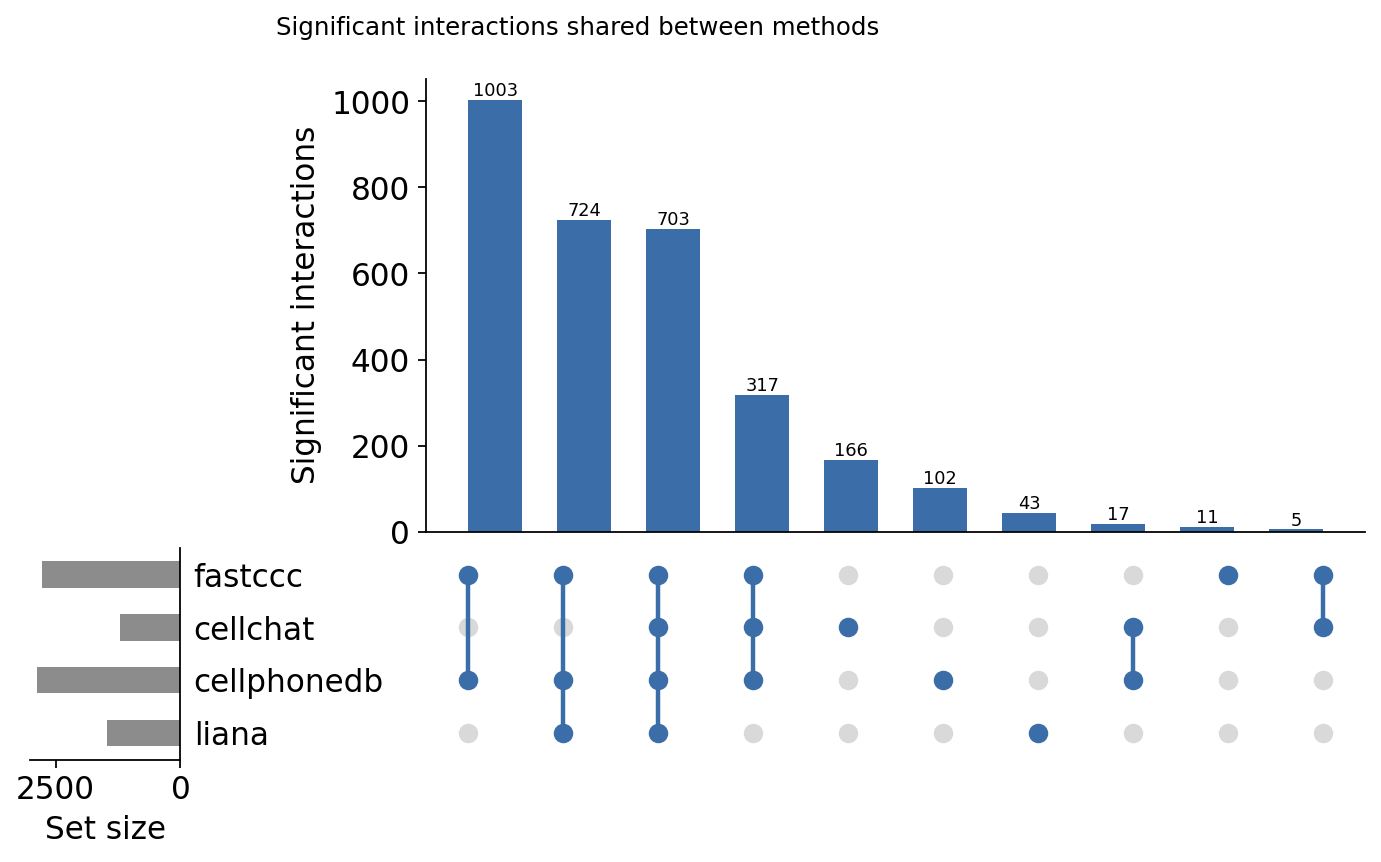

In [12]:
fig = ov.pl.ccc_compare(res, plot_type='upset')

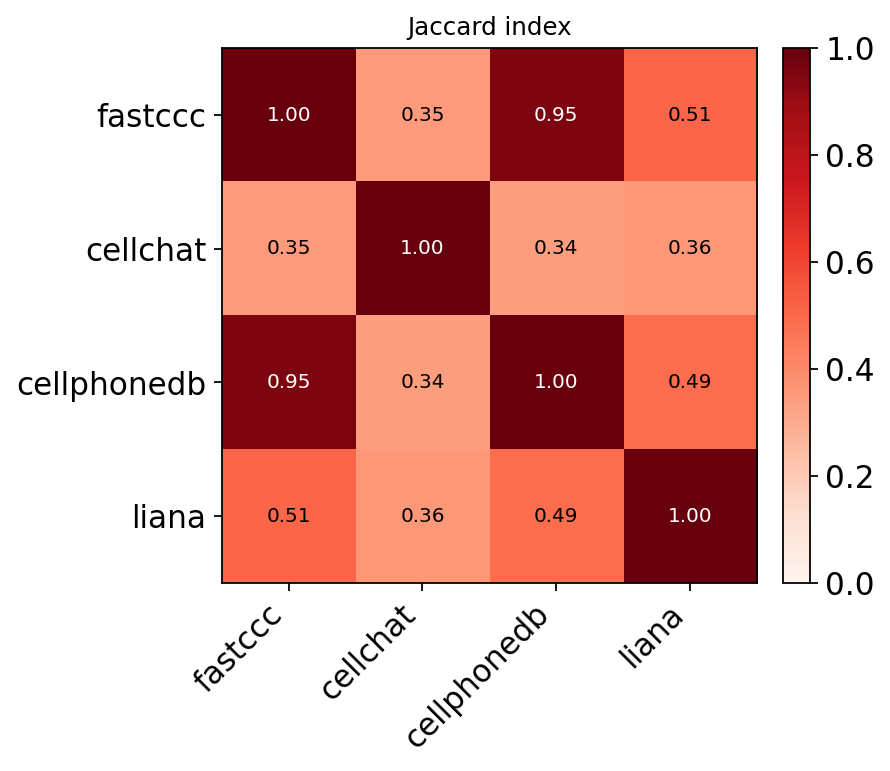

In [13]:
fig = ov.pl.ccc_compare(res, plot_type='jaccard')

`recall.loc[a, b]` is the share of method *a*'s significant interactions that method *b* also calls.

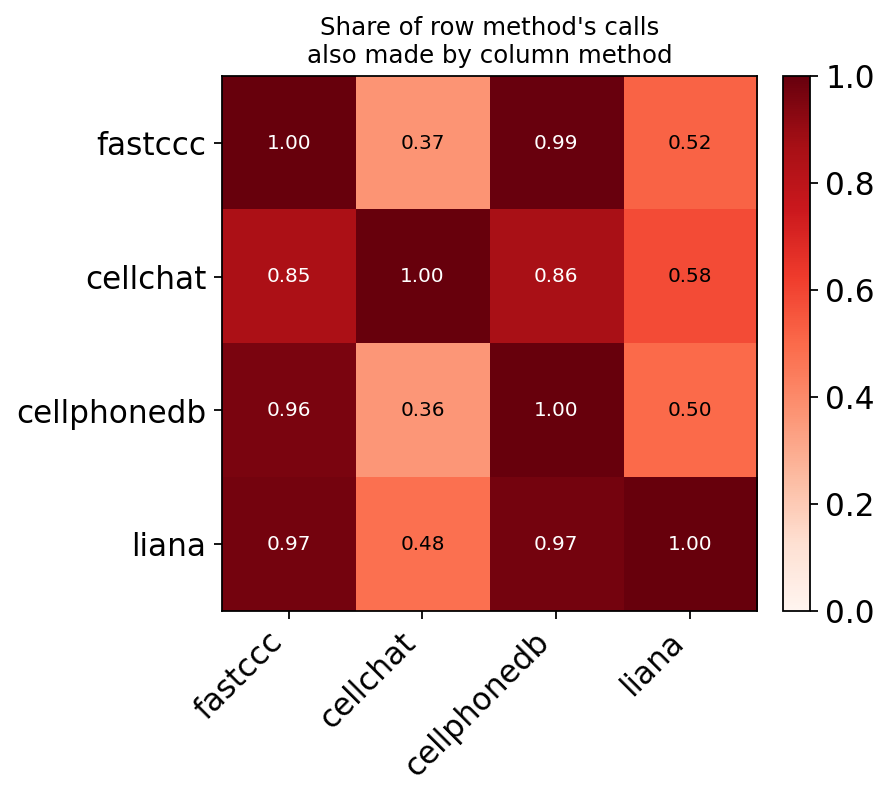

In [14]:
fig = ov.pl.ccc_compare(res, plot_type='recall')

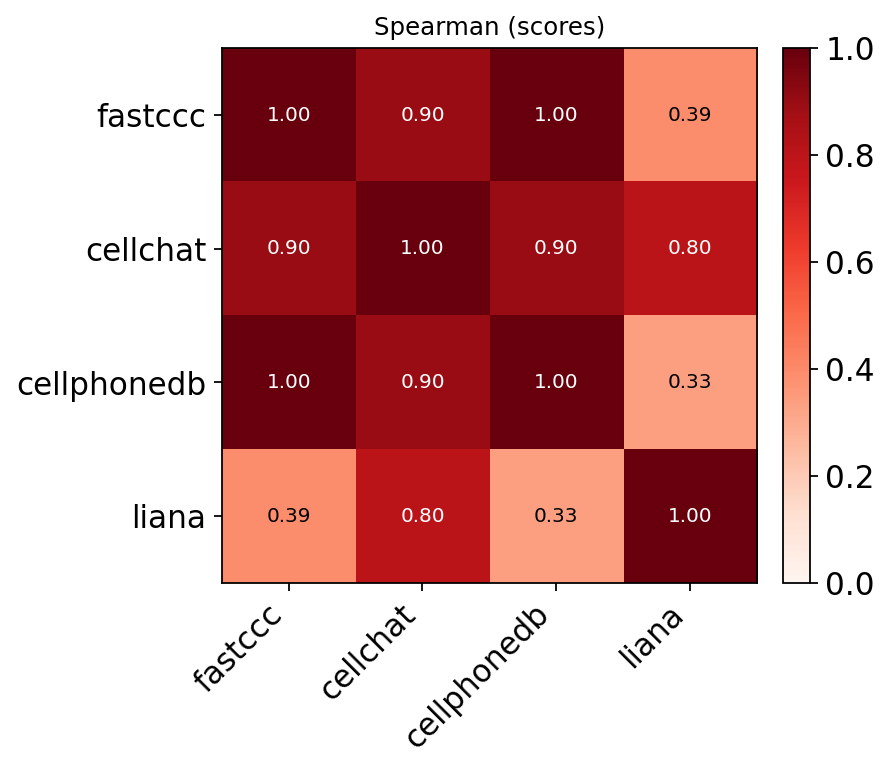

In [15]:
fig = ov.pl.ccc_compare(res, plot_type='score_corr')

On the 1,070 LR pairs present in all four databases:

- **CellChat is the most conservative** (1,208 significant interactions vs ~2,800 for CellPhoneDB/FastCCC): 85–86% of its calls are also made by CellPhoneDB and FastCCC, but only about a third of theirs by CellChat. Its law-of-mass-action score with antagonists and inhibitory co-receptors removes interactions that a mean-expression test keeps.
- **FastCCC and CellPhoneDB agree almost perfectly** (Jaccard 0.95, score Spearman 1.0): FastCCC computes CellPhoneDB's statistic with an analytic null instead of permutations.
- **LIANA** (rank aggregate of several methods) sits in between; 97% of its calls are shared with CellPhoneDB.
- Scores rank interactions similarly (Spearman 0.8–0.9 between CellChat and the others); LIANA's magnitude rank correlates less with mean expression because it aggregates differently scaled scores.

Agreement is higher at the level of ligand-receptor pairs (how many cell pairs use an LR pair) and cell pairs (how many interactions a sender-receiver pair has):

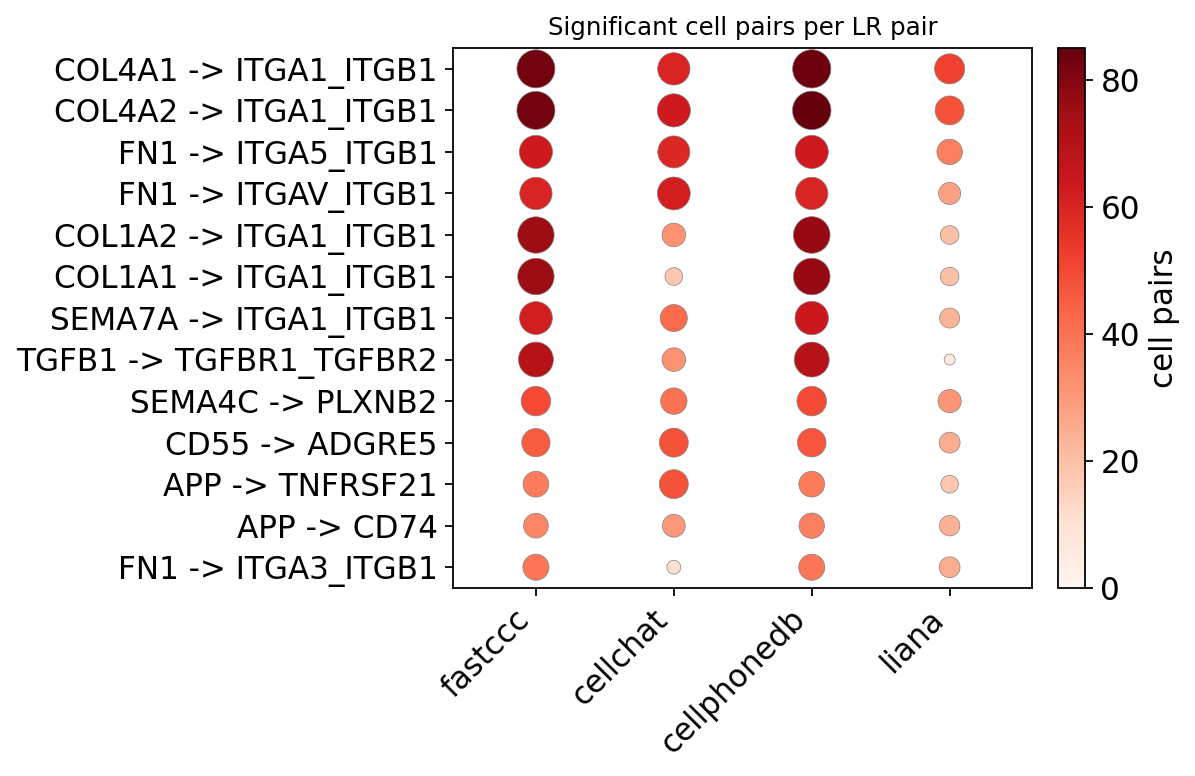

In [16]:
fig = ov.pl.ccc_compare(res, plot_type='top_lr', top_n=8)

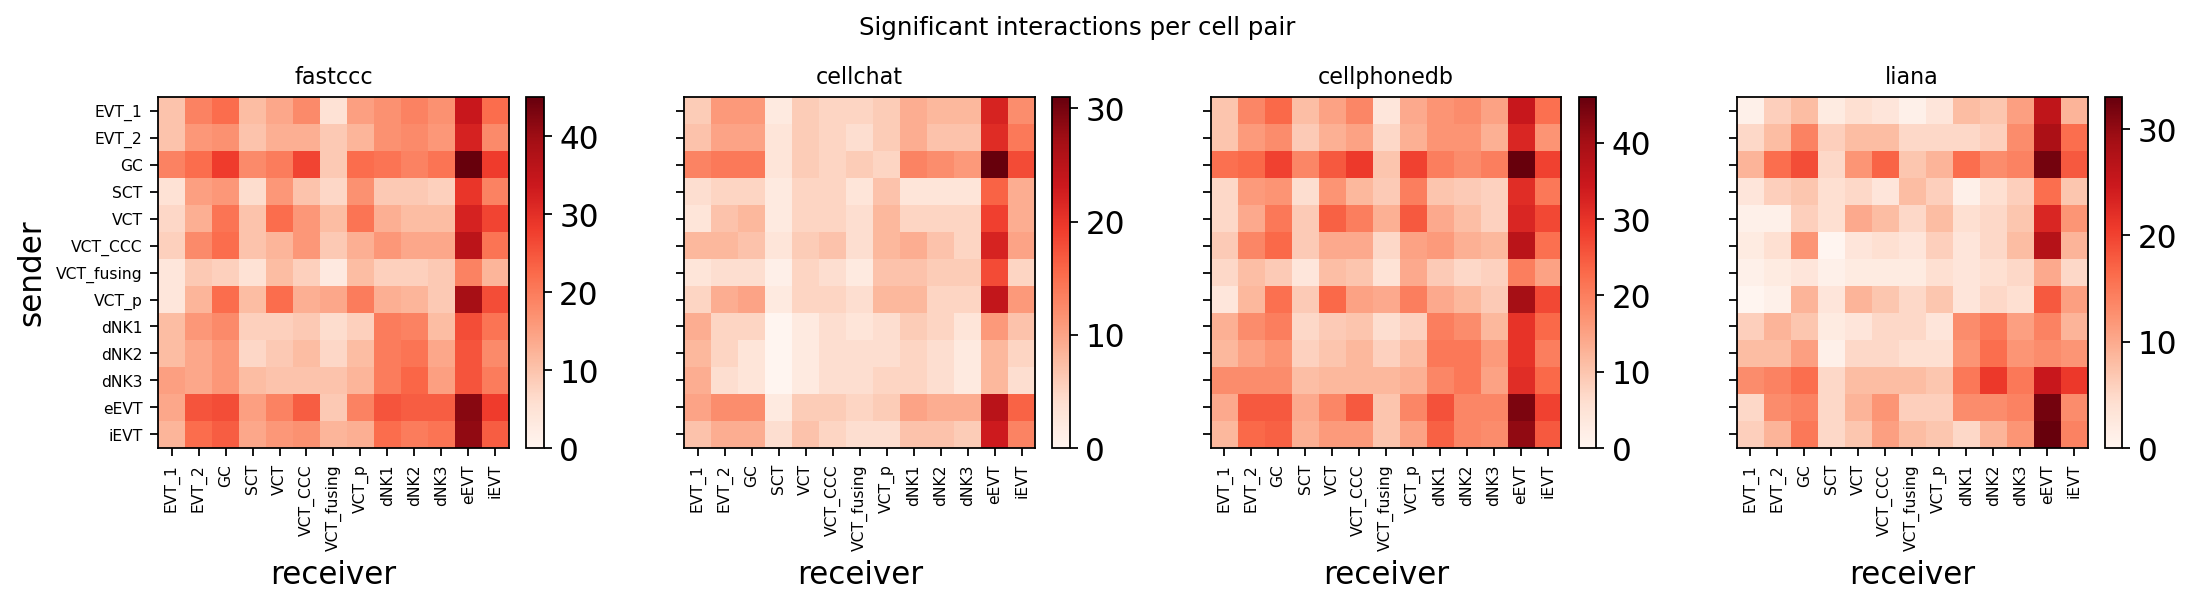

In [17]:
fig = ov.pl.ccc_compare(res, plot_type='cellpair')

In [18]:
res['lr_spearman'].round(2), res['cellpair_pearson'].round(2)

(             fastccc  cellchat  cellphonedb  liana
 fastccc         1.00      0.70         0.99   0.79
 cellchat        0.70      1.00         0.69   0.72
 cellphonedb     0.99      0.69         1.00   0.76
 liana           0.79      0.72         0.76   1.00,
              fastccc  cellchat  cellphonedb  liana
 fastccc         1.00      0.81         0.98   0.85
 cellchat        0.81      1.00         0.78   0.71
 cellphonedb     0.98      0.78         1.00   0.83
 liana           0.85      0.71         0.83   1.00)

At the level of LR pairs and of sender-receiver pairs the methods agree much more than per interaction (Spearman 0.69–0.99 for the number of cell pairs per LR pair, Pearson 0.71–0.98 for interactions per cell pair). The collagen IV / fibronectin – integrin β1 pairs are among the most widespread in all four, and all four identify **eEVT as the main receiver**. Disagreement is mostly about *which* cell pairs pass each method's threshold (e.g. TGFB1–TGFBR1/2 is widespread for CellPhoneDB/FastCCC but rare for LIANA), not about the dominant programmes.

## 5. Plotting the consensus

The consensus is a regular communication AnnData, so every plot of the CellPhoneDB/CellChat tutorials works on it.

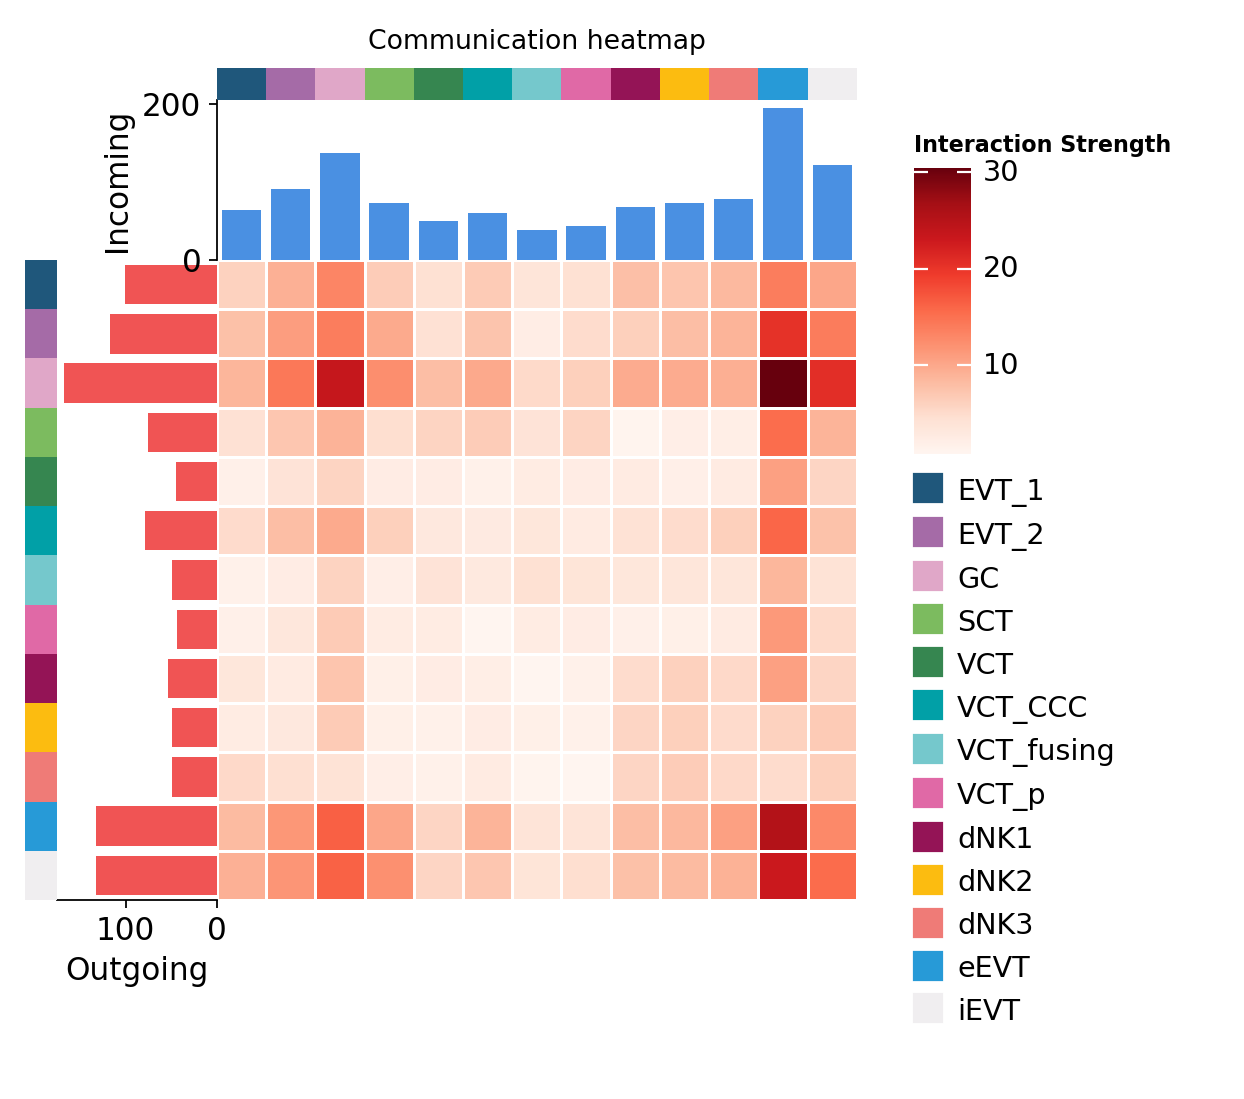

In [19]:
fig, ax = ov.pl.ccc_heatmap(
    comm, plot_type='heatmap', display_by='aggregation', cmap='Reds', show=False,
)

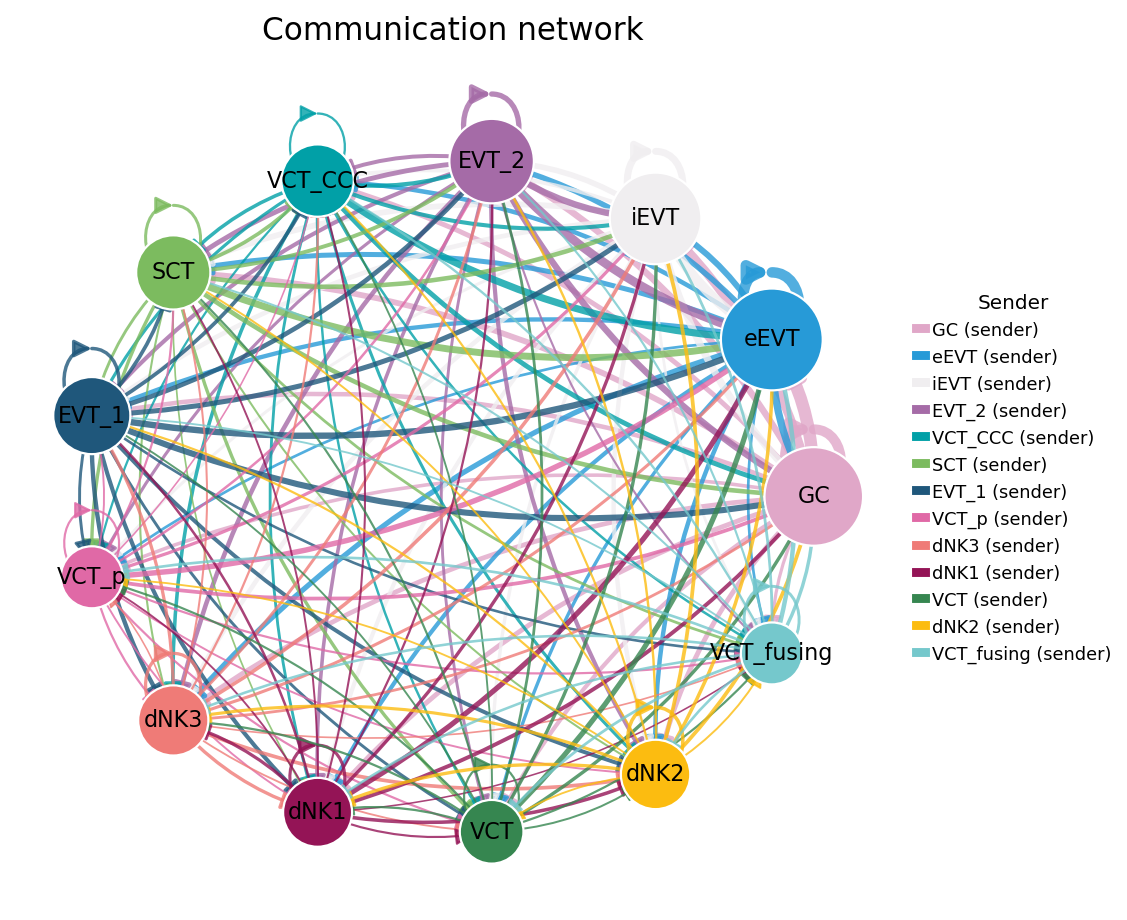

In [20]:
fig, ax = ov.pl.ccc_network_plot(
    comm, plot_type='circle', display_by='aggregation', show=False,
)

🔬 Calculating cell communication strength for 251 pathways...
   - Aggregation method: mean
   - Minimum expression threshold: 2.2250738585072014e-308


✅ Completed pathway communication strength calculation for 251 pathways
📊 Pathway significance analysis results:
   - Total pathways: 251
   - Significant pathways: 49
   - Strength threshold: 0.0
   - p-value threshold: 0.05
🏆 Top 10 pathways by total strength:
----------------------------------------------------------------------------------------------------
Pathway                        Total    Max     Mean    L-R  Active Sig  Rate   Status
----------------------------------------------------------------------------------------------------
CypA                           110.06   0.74    0.65    1    169    104  0.62   ***
VEGF                           68.49    0.75    0.41    11   169    69   0.41   ***
MPZ                            65.68    0.68    0.46    1    144    4    0.03   ***
ADGRE                          65.15    0.79    0.39    4    169    31   0.18   ***
SEMA7                          63.56    0.91    0.44    1    143    10   0.07   ***
FN1                         

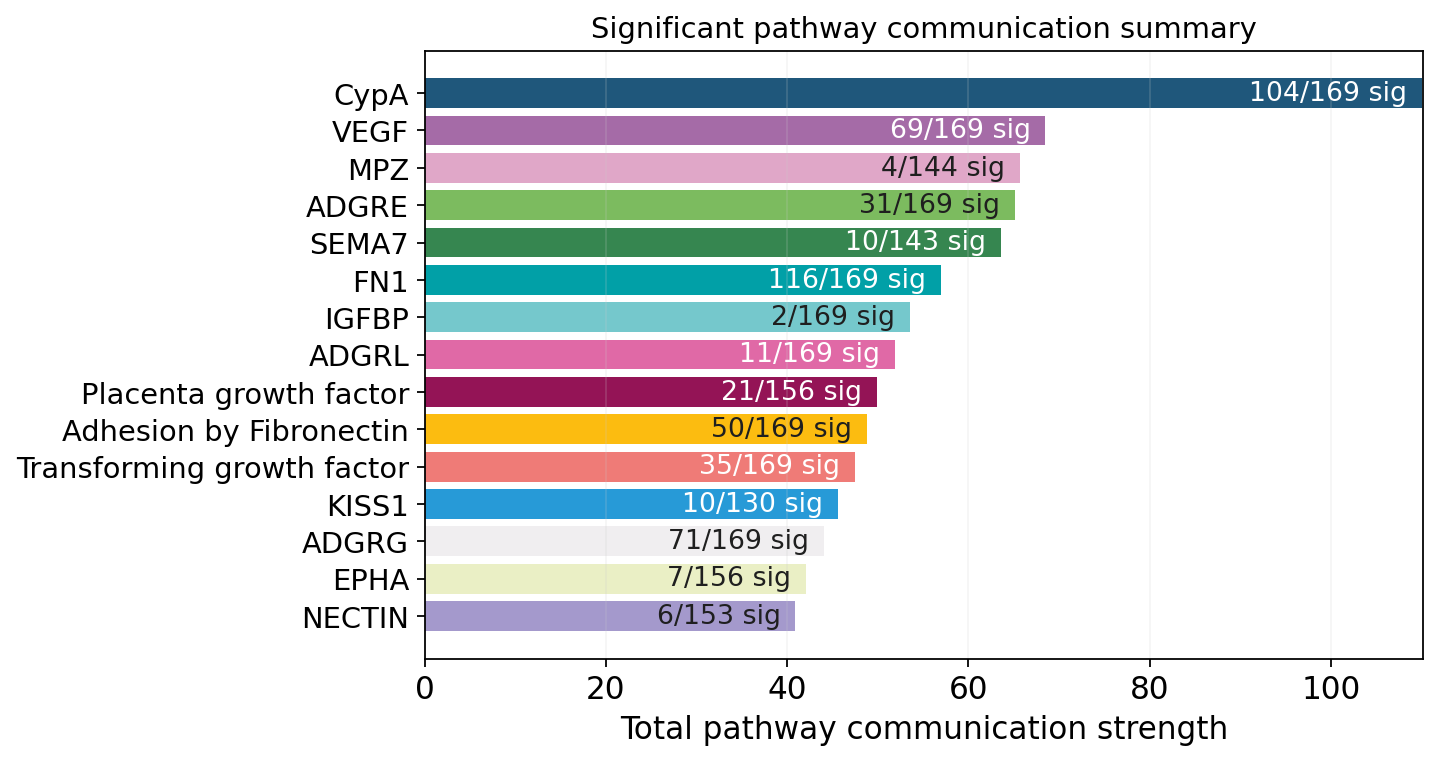

In [21]:
fig, ax = ov.pl.ccc_stat_plot(comm, plot_type='pathway_summary', top_n=15, show=False)

## 6. Spatial communication: `ov.space.run_ccc`

Spatial methods use cell coordinates: CytoSignal scores diffusible and contact-dependent interactions for every cell from its neighbours, COMMOT transports ligand to receptor by optimal transport under a distance limit, and SecAct (with coordinates) relates the expression of secreted proteins to their signalling activity in neighbouring cells. The returned AnnData is aggregated to sender/receiver groups; per-cell scores go to `adata.obsm`.

We use Slide-tags snRNA-seq of E14 mouse brain (Russell *et al.*, *Nature* 2024), the example of the CytoSignal paper: raw counts, 21 annotated cell types, coordinates with 1 unit = 0.73 µm.

In [22]:
sp = ov.datasets.slidetags_mouse_brain()
sp.layers['counts'] = sp.X.copy()
ov.pp.normalize_total(sp, target_sum=1e4)
ov.pp.log1p(sp)
sp

🔍 Downloading data to ./data/slidetags_mouse_brain.h5ad
⚠️ File ./data/slidetags_mouse_brain.h5ad already exists


🔍 Count Normalization:
   Target sum: 10000.0
   Exclude highly expressed: False
✅ Count Normalization Completed Successfully!
   ✓ Processed: 4,623 cells × 26,944 genes
   ✓ Runtime: 0.10s


AnnData object with n_obs × n_vars = 4623 × 26944
    obs: 'cell_type'
    uns: 'source', '_pearson_precompute', 'log1p'
    obsm: 'spatial'
    layers: 'counts'

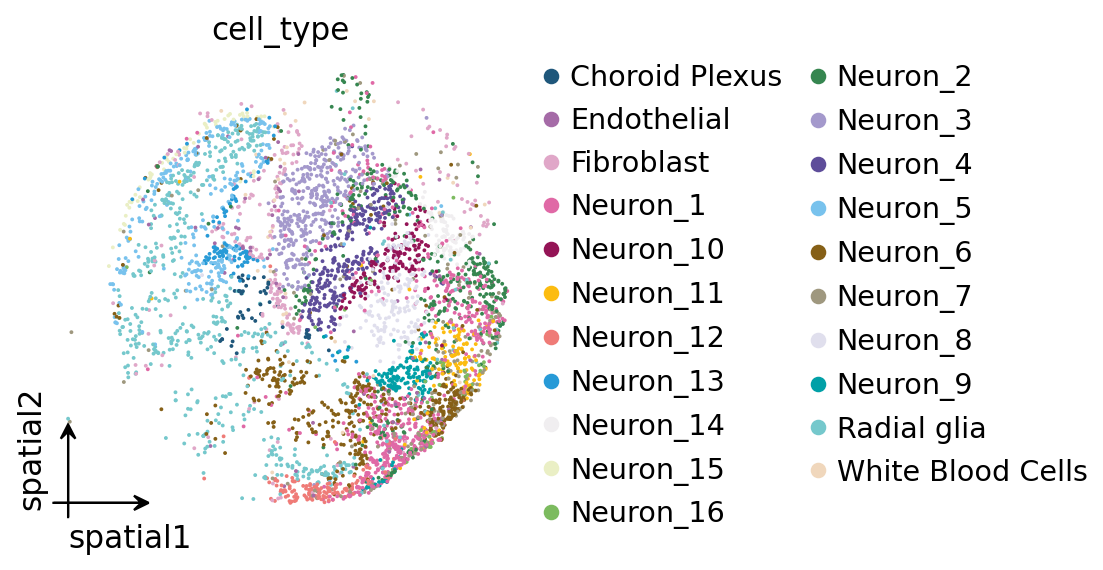

In [23]:
ov.pl.embedding(sp, basis='spatial', color='cell_type', frameon='small', size=12)

CytoSignal and SecAct read `layers['counts']`; COMMOT reads the log-normalised `X`. Distances are given in coordinate units: 200 µm (CytoSignal's diffusion range, also used for COMMOT) is 200 / 0.73 units, and SecAct's 20 µm neighbourhood is 20 / 0.73. COMMOT solves one optimal-transport problem per ligand and receptor over all cell pairs within range, so we restrict it to ten developmental pathways (`pathways=`); CytoSignal and SecAct use their full databases.

In [24]:
um = sp.uns['source']['um_per_unit']
comm_sp = ov.space.run_ccc(
    sp, 'cell_type', method=['cytosignal', 'commot', 'secact'], species='mouse', progress=False,
    method_kwargs={'cytosignal': {'scale_factor': um},
                   'commot': {'dis_thr': 200 / um, 'distance_unit': 'pixel',
                              'pathways': ['NRG', 'PTN', 'MK', 'EPHA', 'SEMA3', 'PDGF', 'BMP', 'WNT', 'ncWNT', 'FGF']},
                   'secact': {'radius': 20 / um}},
)

...start to solve the collective optimal transport problem


...start to solve the row-wise optimal transport problem


...start to solve the column-wise optimal transport problem


...start to solve the block-wise optimal transport problem


In [25]:
for m in ['cytosignal', 'commot', 'secact']:
    top = ov.single.get_ccc(sp, method=m, as_long=True, significant_only=True)
    print(m, len(top)); print(top.nlargest(5, 'score')[['source', 'target', 'interaction', 'score']].to_string(), '\n')

cytosignal 5274
         source     target interaction     score
3943   Neuron_8   Neuron_8  NRG3-ERBB4  6.349653
4040   Neuron_9   Neuron_9  NRG3-ERBB4  6.011135
2209  Neuron_14  Neuron_14  NRG3-ERBB4  5.518165
3131   Neuron_4   Neuron_4  NRG3-ERBB4  4.108535
1367  Neuron_10  Neuron_10  NRG3-ERBB4  2.943975 
commot 8486
           source       target interaction       score
8214  Radial glia  Radial glia  Ptn-Ptprz1  488.065281
7260     Neuron_8     Neuron_8  Nrg3-Erbb4  331.591458
6663     Neuron_6     Neuron_6  Nrg3-Erbb4  310.663488
6661     Neuron_6     Neuron_6  Nrg1-Erbb4  284.173319
7627     Neuron_9     Neuron_9  Nrg3-Erbb4  274.400218 
secact 306
                source             target     interaction     score
61          Fibroblast  White Blood Cells   PLTP→activity  9.828242
302     Choroid Plexus         Fibroblast  RSPO3→activity  9.266612
256          Neuron_11           Neuron_7   CA10→activity  8.273725
50   White Blood Cells        Endothelial   IGF1→activity  7.15

- **CytoSignal**: the strongest diffusible signal is **NRG3 → ERBB4** among cortical neuron subtypes; neuregulin–ErbB4 signalling guides interneuron migration in the developing cortex.
- **COMMOT** recovers NRG3/NRG1 → ERBB4 among the same neurons and adds **PTN/MDK → PTPRZ1** in radial glia, the pleiotrophin/midkine–PTPRζ signal of neural progenitors.
- **SecAct** (secreted-protein activity in neighbouring cells) finds non-neuronal signals, e.g. **RSPO3** from the choroid plexus to fibroblasts (R-spondins, Wnt amplifiers, are made by the choroid plexus and cortical hem) and **IGF1** from immune cells.

CytoSignal's per-cell scores (cells × interactions) show *where* an interaction is active:

In [26]:
sp.obsm['cytosignal_scores'].iloc[:3, :4]

,IL12A_IL12B-IL12RB1_IL12RB2,INHBA_INHBB-ACVR1B_ACVR2A,INHBA_INHBB-ACVR1_ACVR2A,IL12B_IL23A-IL12RB1_IL23R
AAACCCAAGACAGCTG-1,0.000008,0.080814,0.080001,0.0
AAACCCACACACGGAA-1,0.000000,0.003715,0.003896,0.0
AAACCCACAGGTTCCG-1,0.000000,0.226515,0.293405,0.0


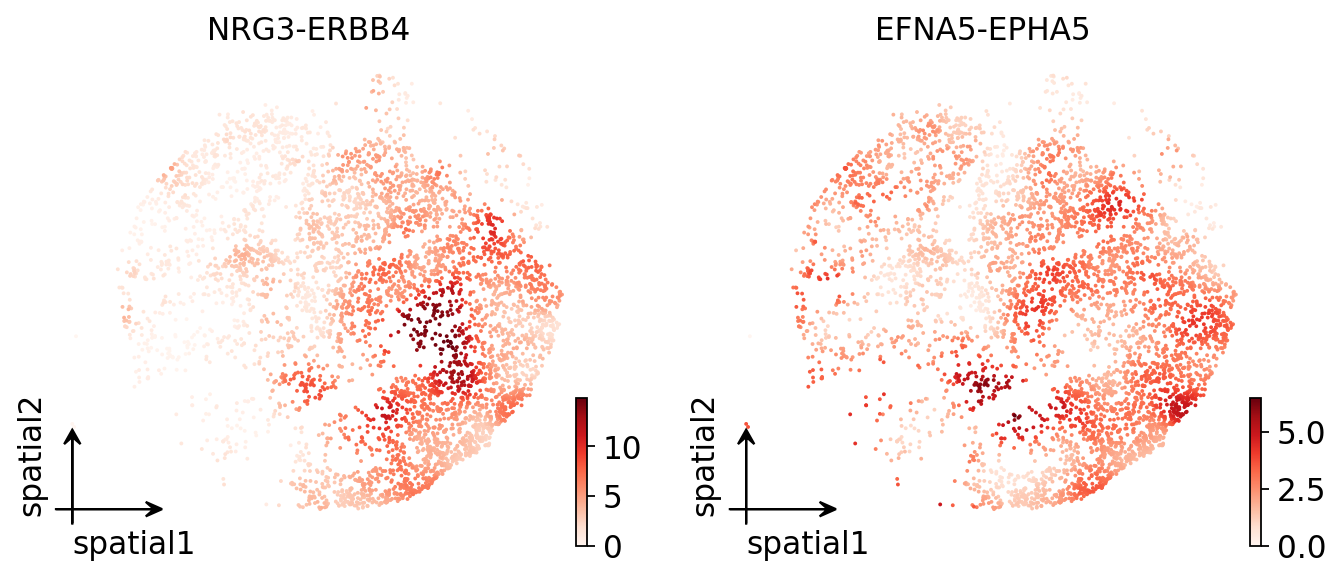

In [27]:
for lr in ['NRG3-ERBB4', 'EFNA5-EPHA5']:
    sp.obs[lr] = sp.obsm['cytosignal_scores'][lr].to_numpy()
ov.pl.embedding(sp, basis='spatial', color=['NRG3-ERBB4', 'EFNA5-EPHA5'],
                frameon='small', size=12, cmap='Reds', ncols=2)

CytoSignal and COMMOT both score ligand-receptor pairs, so they can be compared per LR pair (on the pairs both databases contain):

In [28]:
res_lr = ov.single.compare_ccc(sp, methods=['cytosignal', 'commot'])
print(res_lr['level'], res_lr['universe_size'])
res_lr['n_significant']

lr 356


cytosignal    3645
commot        2462
dtype: int64

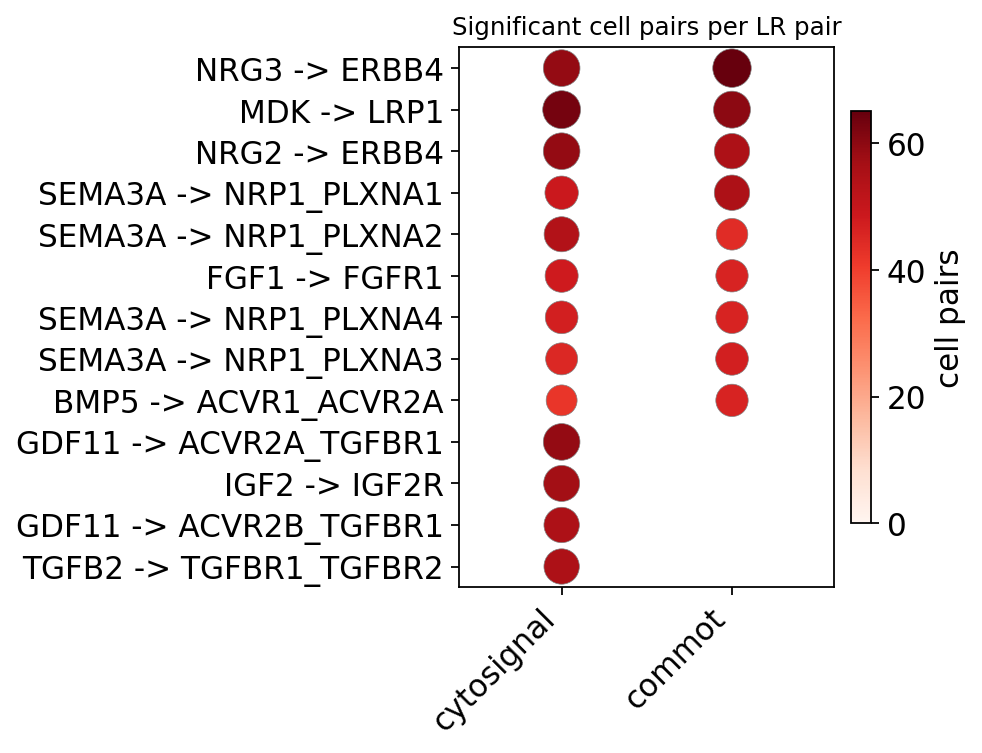

In [29]:
fig = ov.pl.ccc_compare(res_lr, plot_type='top_lr', top_n=8)

Both spatial methods rank **NRG3/NRG2 → ERBB4**, **MDK → LRP1**, **FGF1 → FGFR1** and the **SEMA3A → neuropilin/plexin** receptors among their most widespread pairs. CytoSignal additionally finds GDF11 / TGF-β-family and IGF2 → IGF2R signalling in many cell pairs; COMMOT did not test those pathways here (it was restricted to ten pathways).

SecAct reports secreted proteins (no receptor), so a comparison that includes it automatically switches to the ligand level: sender → receiver signalling per ligand.

In [30]:
res_sp = ov.single.compare_ccc(sp)
print(res_sp['level'], res_sp['universe_size'])
res_sp['n_significant']

ligand 131


cytosignal    1751
commot        2010
secact          22
dtype: int64

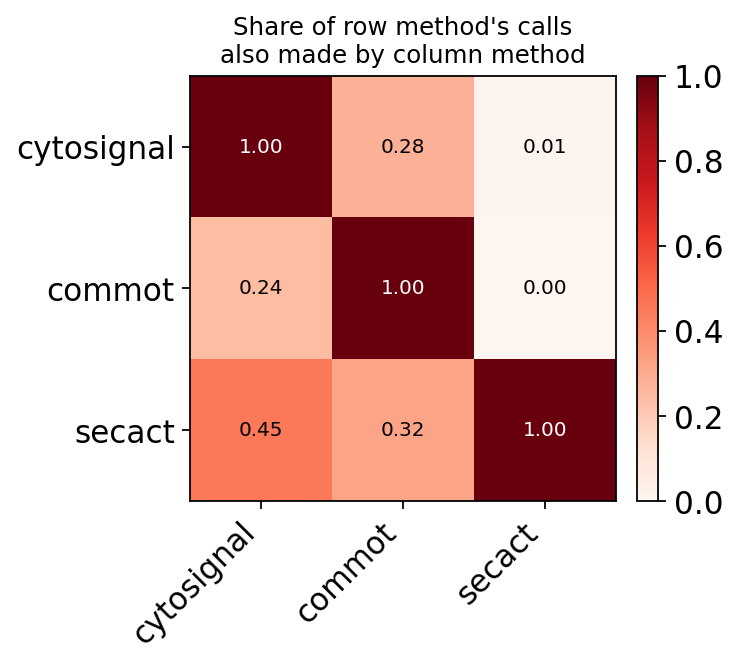

In [31]:
fig = ov.pl.ccc_compare(res_sp, plot_type='recall')

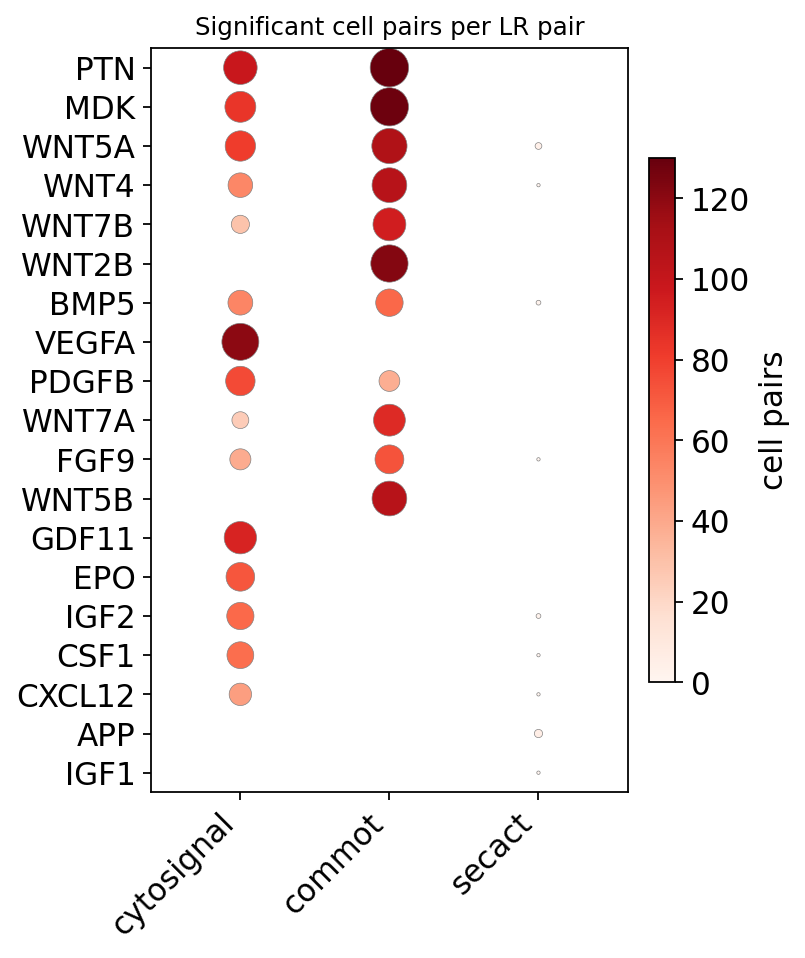

In [32]:
fig = ov.pl.ccc_compare(res_sp, plot_type='top_lr', top_n=8)

SecAct overlaps little with the LR methods (it calls 22 shared-ligand interactions, against ~2,000 for CytoSignal and COMMOT), but 45% of its calls are also made by CytoSignal: activity in the receivers and co-expression of ligand and receptor are complementary evidence, and interactions supported by both are the strongest candidates.

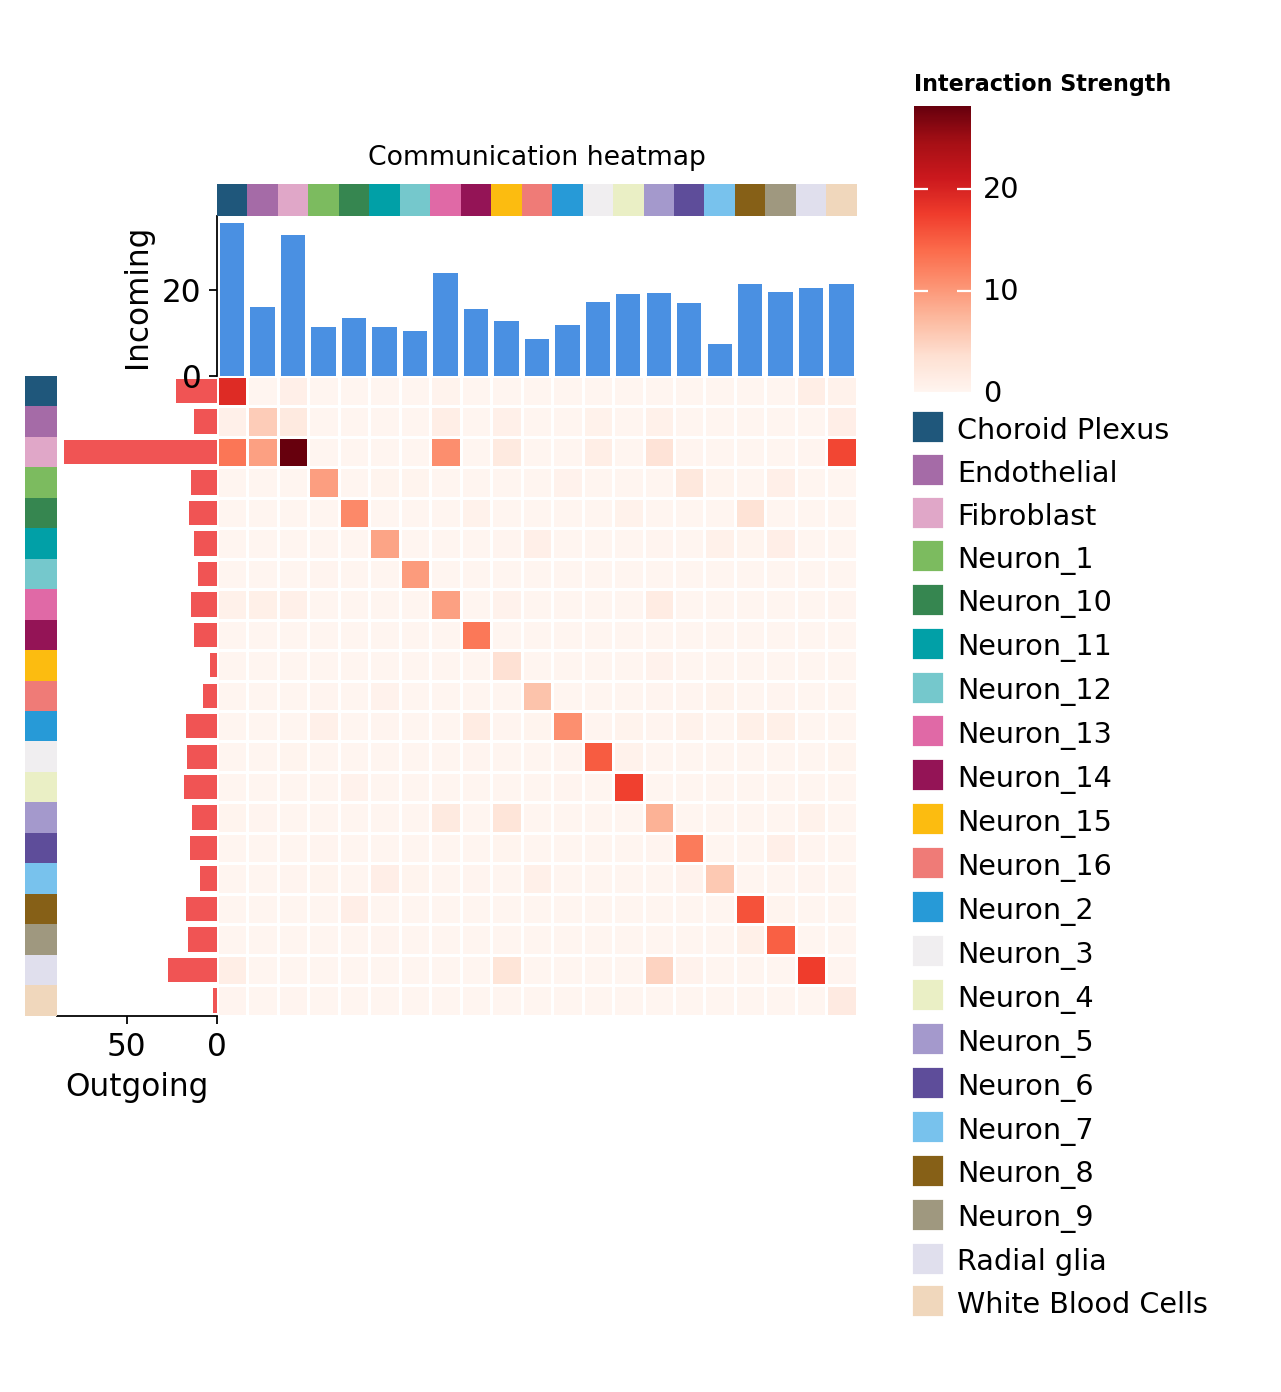

In [33]:
fig, ax = ov.pl.ccc_heatmap(
    ov.single.get_ccc(sp, method='cytosignal'), plot_type='heatmap', display_by='aggregation',
    cmap='Reds', show=False,
)

## Summary

- `ov.single.run_ccc(adata, groupby, method=...)` / `ov.space.run_ccc` run any registered method and return one communication AnnData for `ov.pl.ccc_*`.
- A list of methods adds an RRA or voting consensus with per-method layers.
- `ov.single.compare_ccc` + `ov.pl.ccc_compare` quantify agreement on the interactions every database contains.
- New methods can be plugged in with `ov.single.register_ccc_method`.